In [57]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [58]:
def implot(imgs, titulos, cmap='gray', tamanho=6):
  amount = len(imgs)

  plt.figure(figsize=(tamanho * amount, tamanho))
  for i in range(amount):
    plt.subplot(1, amount, i+1)
    plt.imshow(imgs[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')

  plt.show()

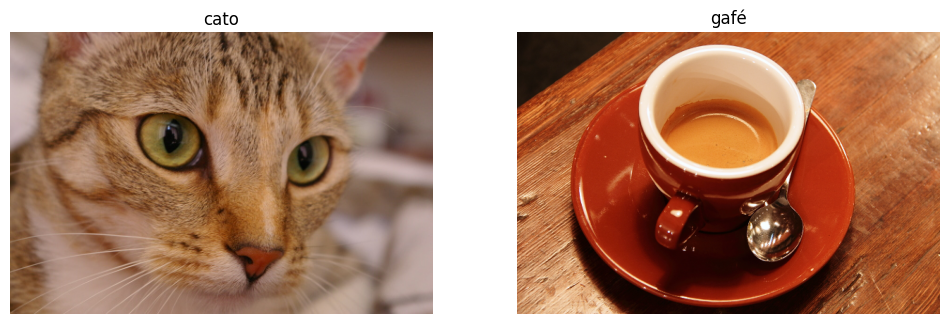

In [59]:
implot([data.cat(), data.coffee()], ['cato', 'gafé'])

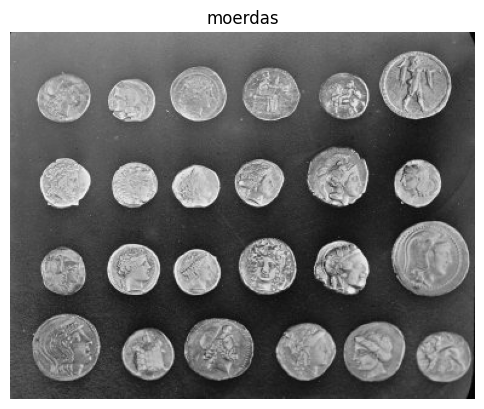

In [60]:
moedas = data.coins()
implot([moedas], ['moerdas'])

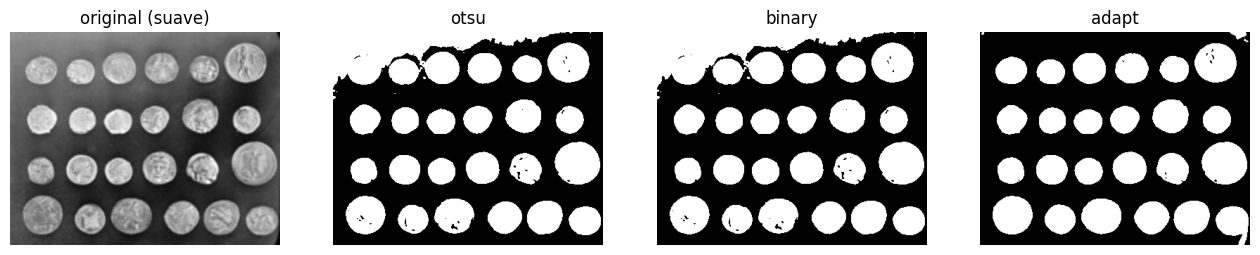

In [61]:
moedas_suave = cv2.GaussianBlur(moedas, (5,5), 0)
_, mascara_moedas_otsu = cv2.threshold(moedas_suave, 0, 255, cv2.THRESH_OTSU)
_, mascara_moedas_binary = cv2.threshold(moedas_suave, 0, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY)
mascara_moedas_adapt = cv2.adaptiveThreshold(moedas_suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 101, -10)

implot([moedas_suave, mascara_moedas_otsu, mascara_moedas_binary, mascara_moedas_adapt],
        ['original (suave)', 'otsu', 'binary', 'adapt'], tamanho = 4)

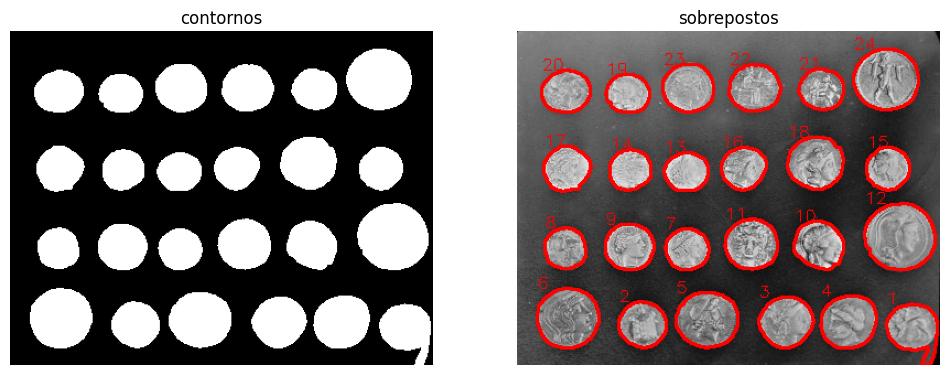

In [62]:
mascara_moedas_contornos, _ = cv2.findContours(mascara_moedas_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

moedas_contornos = [c for c in mascara_moedas_contornos if cv2.contourArea(c) > 500]
img_moedas_contornos = np.zeros_like(mascara_moedas_adapt)

cv2.drawContours(img_moedas_contornos, moedas_contornos, -1, 255, thickness=-1)

moedas = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)

cv2.drawContours(moedas, moedas_contornos, -1, (255,0,0), 2)

for i, c in enumerate(moedas_contornos):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(moedas, str(i+1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0))

implot([img_moedas_contornos, moedas],
        ['contornos', 'sobrepostos'])